# Explain the churn model to a retention manager

The retention manager: "Before my team acts on this list, I want to know what the model looks at, and why it put customer 5194 on it. And should we push everyone onto two-year contracts?" You explain the boosted churn model three ways, then write the answer for someone who does not read code.

## The starter

The cell fits `make_pipeline(tree_pre, HistGradientBoostingClassifier(random_state=42))` on the 5,634 training customers and prints its test ROC AUC. `tree_pre` imputes and one-hot encodes but does not scale, so every value you read is in months, dollars or categories.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

df = pd.read_csv("data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["customerID", "Churn"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)


def make_tree_pre(X):
    """Impute and one-hot encode, no scaling; output columns keep readable names (tenure, Contract_Two year)."""
    num_cols = list(X.select_dtypes(include="number").columns)
    cat_cols = list(X.select_dtypes(include=["str", "object"]).columns)
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


tree_pre = make_tree_pre(X)
model = make_pipeline(tree_pre, HistGradientBoostingClassifier(random_state=42)).fit(X_train, y_train)
print("test ROC AUC", round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3))

test ROC AUC 0.835


## Step 1 · Permutation importance on the test customers

`permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)`. Put `importances_mean` and `importances_std` in a table sorted from largest to smallest.

In [2]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std},
                   index=X_test.columns).sort_values("mean", ascending=False)
imp.round(3)

,mean,std
Contract,0.125,0.008
tenure,0.049,0.006
InternetService,0.016,0.003
TotalCharges,0.008,0.004
OnlineSecurity,0.008,0.002
MonthlyCharges,0.007,0.004
TechSupport,0.004,0.002
PaperlessBilling,0.003,0.002
MultipleLines,0.003,0.002
SeniorCitizen,0.002,0.001


## Step 2 · Which columns matter?

Which columns lose the most ROC AUC when shuffled? Which ones lose almost nothing?

In [3]:
print("largest losses:", ", ".join(imp.index[:3]))
print("almost nothing:", ", ".join(imp.index[imp["mean"] < 0.002]))

largest losses: Contract, tenure, InternetService
almost nothing: SeniorCitizen, gender, StreamingMovies, PaymentMethod, StreamingTV, PhoneService, Partner, OnlineBackup, DeviceProtection, Dependents


## Step 3 · Partial dependence on `tenure`, with ICE lines

`PartialDependenceDisplay.from_estimator(model, X_test_f, ["tenure"], kind="both", subsample=50, random_state=42)`, where `X_test_f = X_test.astype({"tenure": "float64"})`. Read the average curve at 0 and at 72 months.

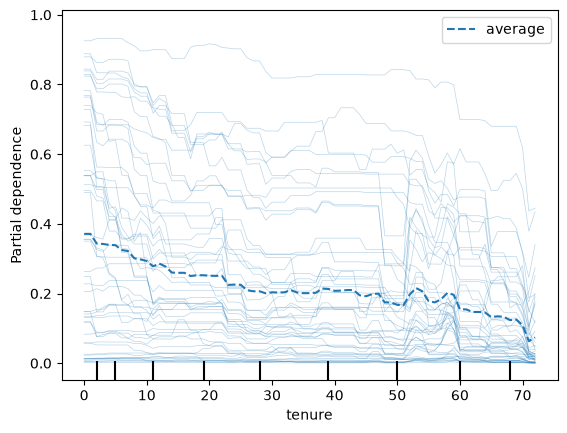

average predicted churn: 0.371 at tenure 0, 0.074 at 72 months
ICE values at tenure 0, all 1,409 test customers: 0.001 to 0.960


In [4]:
from sklearn.inspection import PartialDependenceDisplay

X_test_f = X_test.astype({"tenure": "float64"})       # partial dependence refuses integer columns
display = PartialDependenceDisplay.from_estimator(model, X_test_f, ["tenure"], kind="both", subsample=50,
                                                  random_state=42)
plt.show()

# The average curve uses every test customer; subsample=50 only limits the ICE lines drawn.
# pd_results holds the numbers behind the plot: one grid value per month, 0 to 72.
res = display.pd_results[0]
grid, avg, ice = res["grid_values"][0], res["average"][0], res["individual"][0]
at0, at72 = int(np.argmax(grid == 0)), int(np.argmax(grid == 72))
print(f"average predicted churn: {avg[at0]:.3f} at tenure 0, {avg[at72]:.3f} at 72 months")
print(f"ICE values at tenure 0, all {ice.shape[0]:,} test customers: {ice[:, at0].min():.3f} to {ice[:, at0].max():.3f}")

## Step 4 · Partial dependence on `Contract`

Use `categorical_features=["Contract"]`. Read the three values.

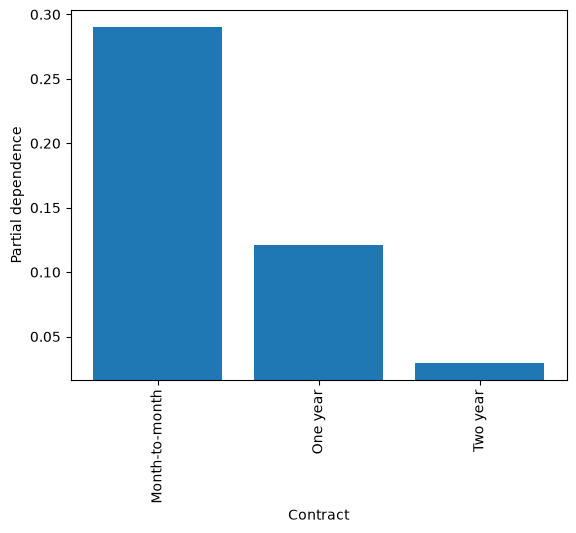

{'Month-to-month': 0.29, 'One year': 0.121, 'Two year': 0.03}

In [5]:
cdisplay = PartialDependenceDisplay.from_estimator(model, X_test_f, ["Contract"], categorical_features=["Contract"])
plt.show()
cres = cdisplay.pd_results[0]
contract_pd = dict(zip(cres["grid_values"][0], cres["average"][0]))
{k: round(float(v), 3) for k, v in contract_pd.items()}

## Step 5 · One customer, explained with SHAP

Transform the test rows with the fitted preprocessing (`Xt = model[0].transform(X_test)`), build `explainer = shap.TreeExplainer(model[-1])` and `sv = explainer(Xt)`, then draw `shap.plots.waterfall(sv[i])` for the row of customer 5194 (`i = list(X_test.index).index(5194)`).

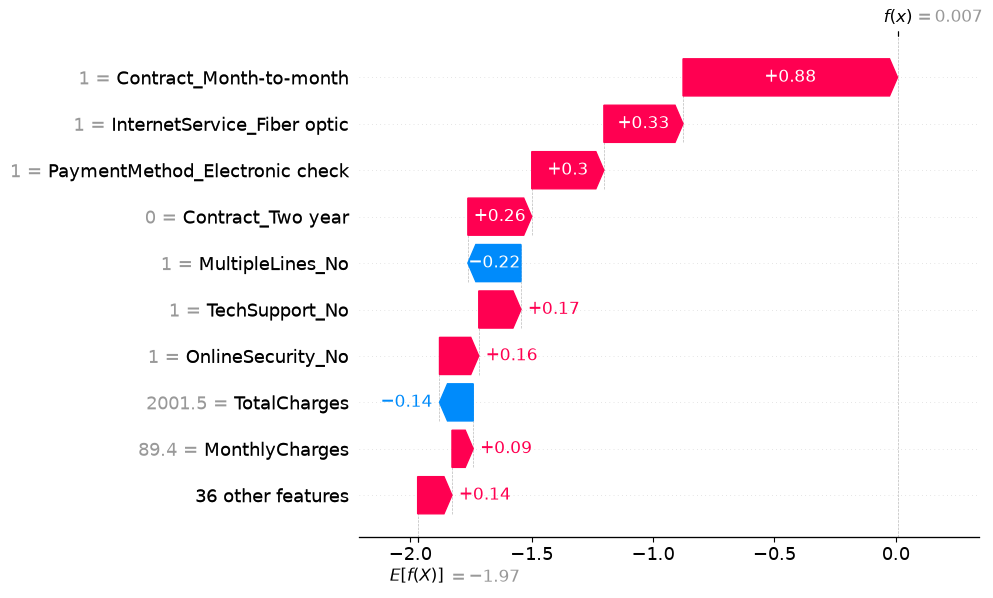

customer 5194: tenure 22 months, Month-to-month, Fiber optic, 89.4 a month; probability 0.502
largest pushes (log-odds): Contract_Month-to-month +0.88, InternetService_Fiber optic +0.33, PaymentMethod_Electronic check +0.30
base value: -1.9697


In [6]:
import shap

Xt = model[0].transform(X_test)
explainer = shap.TreeExplainer(model[-1])
sv = explainer(Xt)
i = list(X_test.index).index(5194)
shap.plots.waterfall(sv[i])

c = X_test.loc[5194]
proba_5194 = model.predict_proba(X_test.loc[[5194]])[0, 1]
pushes = pd.Series(sv.values[i], index=Xt.columns)
top3 = pushes.abs().sort_values(ascending=False).index[:3]
print(f"customer 5194: tenure {c['tenure']} months, {c['Contract']}, {c['InternetService']}, "
      f"{c['MonthlyCharges']} a month; probability {proba_5194:.3f}")
print("largest pushes (log-odds):", ", ".join(f"{k} {pushes[k]:+.2f}" for k in top3))
print("base value:", round(float(np.ravel(sv.base_values)[0]), 4))

## Step 6 · The beeswarm

`shap.plots.beeswarm(sv)`. Which color sits on the right for `tenure`, and what does that mean?

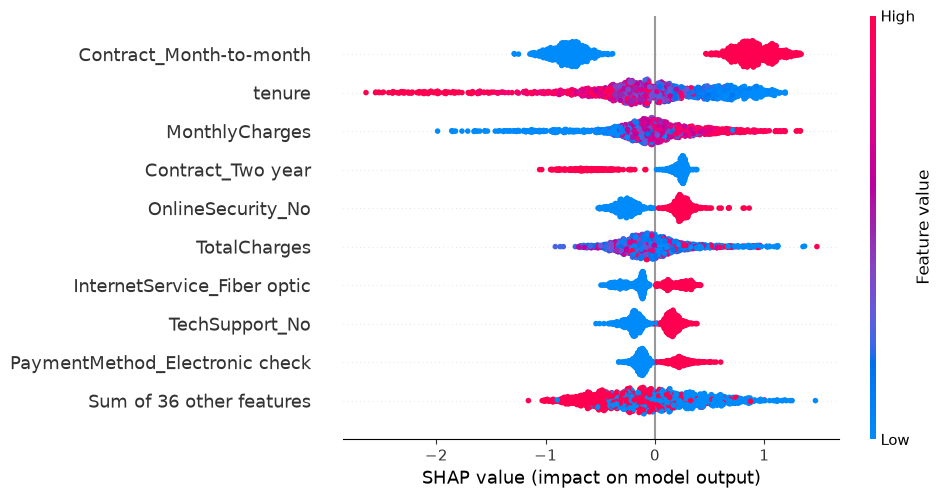

In [7]:
shap.plots.beeswarm(sv)

**Answer.** For `tenure`, the blue dots (low values) sit on the right: a short tenure pushes the prediction toward churn, and a long one pushes it away.

## Step 7 · Four sentences for the manager

What does the model look at, why customer 5194, and should we push everyone onto two-year contracts? Use the top two columns from step 1 and the three largest pushes from step 5. Then say whether a model that predicts churn tells you what happens when you change a customer's contract.

In [8]:
print(f"""The model leans most on the contract type and on how long the customer has been with us (tenure): these two
lower its test ROC AUC, the quality of its ranking, the most when their values are shuffled. Customer 5194 is on the list mainly because they pay
month to month, have fiber internet and pay by electronic check; together these lift the predicted risk to
{proba_5194:.0%}. The model shows that two-year customers churn less, not that moving someone to a two-year
contract would keep them: customers who choose long contracts may differ in other ways. To find out, offer the
contract change to a random half of a group of customers and compare the two halves.""")

The model leans most on the contract type and on how long the customer has been with us (tenure): these two
lower its test ROC AUC, the quality of its ranking, the most when their values are shuffled. Customer 5194 is on the list mainly because they pay
month to month, have fiber internet and pay by electronic check; together these lift the predicted risk to
50%. The model shows that two-year customers churn less, not that moving someone to a two-year
contract would keep them: customers who choose long contracts may differ in other ways. To find out, offer the
contract change to a random half of a group of customers and compare the two halves.


## Bonus · Drop `TotalCharges`

In [9]:
X_train_d, X_test_d = X_train.drop(columns=["TotalCharges"]), X_test.drop(columns=["TotalCharges"])
model_d = make_pipeline(make_tree_pre(X_train_d), HistGradientBoostingClassifier(random_state=42)).fit(X_train_d, y_train)
pi_d = permutation_importance(model_d, X_test_d, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
tenure_without = pd.Series(pi_d.importances_mean, index=X_test_d.columns)["tenure"]
print(f"tenure importance: {imp.loc['tenure', 'mean']:.3f} with TotalCharges, {tenure_without:.3f} without")

tenure importance: 0.049 with TotalCharges, 0.080 without


## Check yourself

In [10]:
check = {"Starter · test ROC AUC": round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3)}
for col in ("Contract", "tenure", "InternetService", "gender"):
    check[f"Step 1 · {col}"] = f"{imp.loc[col, 'mean']:.3f} ± {imp.loc[col, 'std']:.3f}"
check.update({
    "Step 3 · average at tenure 0": round(avg[at0], 3),
    "Step 3 · average at 72 months": round(avg[at72], 3),
    "Step 3 · ICE range at tenure 0": f"{ice[:, at0].min():.3f} to {ice[:, at0].max():.3f}",
    "Step 4 · Month-to-month": round(float(contract_pd["Month-to-month"]), 3),
    "Step 4 · One year": round(float(contract_pd["One year"]), 3),
    "Step 4 · Two year": round(float(contract_pd["Two year"]), 3),
    "Step 5 · customer": f"tenure {c['tenure']} months, {c['Contract']}, {c['InternetService']}, MonthlyCharges {c['MonthlyCharges']}",
    "Step 5 · probability": round(proba_5194, 3),
    "Step 5 · largest pushes": ", ".join(f"{k} {pushes[k]:+.2f}" for k in top3),
    "Step 5 · base value": round(float(np.ravel(sv.base_values)[0]), 4),
    "Bonus · tenure without TotalCharges": round(tenure_without, 3),
})
for label, value in check.items():
    print(f"{label:<38} {value}")

Starter · test ROC AUC                 0.835
Step 1 · Contract                      0.125 ± 0.008
Step 1 · tenure                        0.049 ± 0.006
Step 1 · InternetService               0.016 ± 0.003
Step 1 · gender                        0.001 ± 0.001
Step 3 · average at tenure 0           0.371
Step 3 · average at 72 months          0.074
Step 3 · ICE range at tenure 0         0.001 to 0.960
Step 4 · Month-to-month                0.29
Step 4 · One year                      0.121
Step 4 · Two year                      0.03
Step 5 · customer                      tenure 22 months, Month-to-month, Fiber optic, MonthlyCharges 89.4
Step 5 · probability                   0.502
Step 5 · largest pushes                Contract_Month-to-month +0.88, InternetService_Fiber optic +0.33, PaymentMethod_Electronic check +0.30
Step 5 · base value                    -1.9697
Bonus · tenure without TotalCharges    0.08
